In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
DATASET_PATH = PROJECT_ROOT / "data" / "raw"
RATING_PATH = DATASET_PATH / "ratings.csv"

ratings = pd.read_csv(
    RATING_PATH, 
    encoding="latin-1"
)

ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit="s")

In [13]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,2000-07-30 18:45:03
1,1,3,4.0,2000-07-30 18:20:47
2,1,6,4.0,2000-07-30 18:37:04
3,1,47,5.0,2000-07-30 19:03:35
4,1,50,5.0,2000-07-30 18:48:51


In [15]:
print("Размер таблицы:", ratings.shape)
print("\nТипы данных:")
print(ratings.dtypes)

print("\nПропуски:")
print(ratings.isna().sum())

print("\nКоличество дубликатов:")
print(ratings.duplicated(["userId", "movieId"]).sum())

print("\nПериод оценок:")
print(ratings["timestamp"].min(), "—", ratings["timestamp"].max())

print("\nКоличество пользователей:", ratings["userId"].nunique())
print("Количество фильмов:", ratings["movieId"].nunique())

Размер таблицы: (100836, 4)

Типы данных:
userId               int64
movieId              int64
rating             float64
timestamp    datetime64[s]
dtype: object

Пропуски:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Количество дубликатов:
0

Период оценок:
1996-03-29 18:36:55 — 2018-09-24 14:27:30

Количество пользователей: 610
Количество фильмов: 9724


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


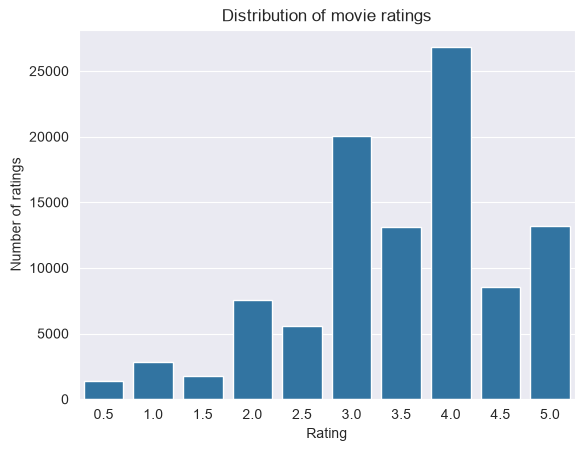

In [16]:
print(ratings["rating"].value_counts().sort_index())

sns.countplot(data=ratings, x="rating")
plt.title("Distribution of movie ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

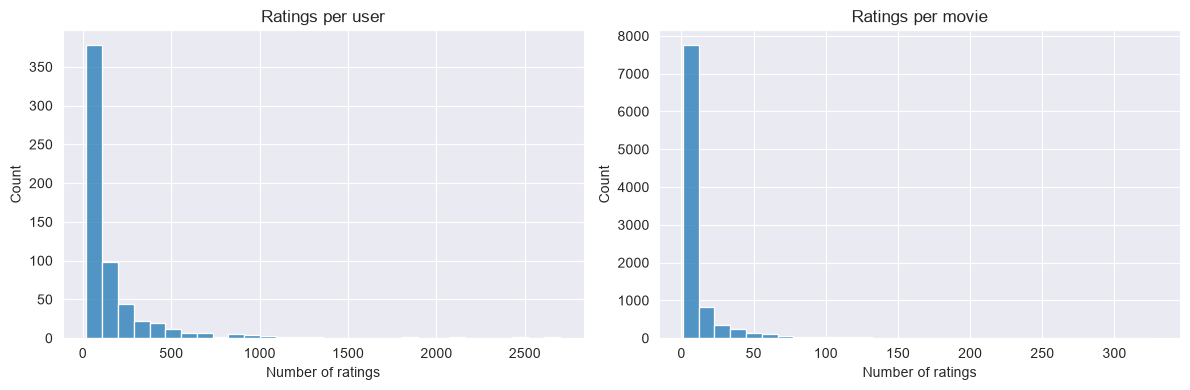

In [17]:
user_activity = ratings.groupby("userId").size()
movie_popularity = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(user_activity, bins=30, ax=axes[0])
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings")

sns.histplot(movie_popularity, bins=30, ax=axes[1])
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("Number of ratings")

plt.tight_layout()
plt.show()

In [18]:
ratings = ratings.sort_values(
    ["userId", "timestamp", "movieId"]
).reset_index(drop=True)

train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("userId", sort=False):
    split_idx = int(len(user_ratings) * 0.8)

    train_parts.append(user_ratings.iloc[:split_idx])
    test_parts.append(user_ratings.iloc[split_idx:])

train = pd.concat(train_parts).reset_index(drop=True)
test = pd.concat(test_parts).reset_index(drop=True)

print(f"Train: {len(train):,} оценок")
print(f"Test:  {len(test):,} оценок")
print(f"Доля test: {len(test) / len(ratings):.1%}")

Train: 80,419 оценок
Test:  20,417 оценок
Доля test: 20.2%


In [20]:
assert len(train) + len(test) == len(ratings)
assert train["userId"].nunique() == ratings["userId"].nunique()
assert test["userId"].nunique() == ratings["userId"].nunique()

print("Пользователи только в test:",
      len(set(test["userId"]) - set(train["userId"])))

print("Фильмы в test, которых нет в train:",
      len(set(test["movieId"]) - set(train["movieId"])))

Пользователи только в test: 0
Фильмы в test, которых нет в train: 1494


In [21]:
POSITIVE_THRESHOLD = 4

train_positive = train[train["rating"] >= POSITIVE_THRESHOLD].copy()
test_positive = test[test["rating"] >= POSITIVE_THRESHOLD].copy()

print("Положительных примеров в train:", len(train_positive))
print("Положительных примеров в test:", len(test_positive))
print(
    "Доля положительных оценок в test:",
    f"{len(test_positive) / len(test):.1%}"
)

Положительных примеров в train: 39071
Положительных примеров в test: 9509
Доля положительных оценок в test: 46.6%


In [22]:
from datetime import datetime

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

train_path = PROCESSED_DIR / f"train_{run_id}.csv"
test_path = PROCESSED_DIR / f"test_{run_id}.csv"

train.to_csv(train_path, index=False)
test.to_csv(test_path, index=False)

print("Выборки сохранены:")
print(f"Train: {train_path}")
print(f"Test:  {test_path}")
print(f"Размер train: {train.shape}")
print(f"Размер test:  {test.shape}")

Выборки сохранены:
Train: C:\IT\movie-recommender-pytorch\data\processed\train_20261020_161901.csv
Test:  C:\IT\movie-recommender-pytorch\data\processed\test_20261020_161901.csv
Размер train: (80419, 4)
Размер test:  (20417, 4)


In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATASET_PATH = PROJECT_ROOT / "data" / "processed"
TRAIN_PATH = DATASET_PATH / "train_20261020_161901.csv"
TEST_PATH = DATASET_PATH / "test_20261020_161901.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

train.head()

,userId,movieId,rating,timestamp
0,1,804,4.0,2000-07-30 18:08:19
1,1,1210,5.0,2000-07-30 18:08:19
2,1,2018,5.0,2000-07-30 18:08:43
3,1,2628,4.0,2000-07-30 18:08:43
4,1,2826,4.0,2000-07-30 18:08:43


In [2]:
import numpy as np
import torch

# Уникальные пользователи и фильмы, известные на обучении
user_ids = np.sort(train["userId"].unique())
movie_ids = np.sort(train["movieId"].unique())

# Перевод исходных ID в индексы от 0 до N-1
user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
movie_to_idx = {movie_id: idx for idx, movie_id in enumerate(movie_ids)}

# Создаём копии, чтобы не изменять исходные таблицы
train_model = train.copy()
test_model = test.copy()

train_model["user_idx"] = train_model["userId"].map(user_to_idx)
train_model["movie_idx"] = train_model["movieId"].map(movie_to_idx)

test_model["user_idx"] = test_model["userId"].map(user_to_idx)
test_model["movie_idx"] = test_model["movieId"].map(movie_to_idx)

# Оставляем в тесте только пары, для которых известны оба эмбеддинга
test_known = test_model.dropna(subset=["user_idx", "movie_idx"]).copy()

train_model["user_idx"] = train_model["user_idx"].astype("int64")
train_model["movie_idx"] = train_model["movie_idx"].astype("int64")
test_known["user_idx"] = test_known["user_idx"].astype("int64")
test_known["movie_idx"] = test_known["movie_idx"].astype("int64")

print("Пользователей в train:", len(user_ids))
print("Фильмов в train:", len(movie_ids))
print("Обучающих оценок:", len(train_model))
print("Тестовых оценок всего:", len(test_model))
print("Тестовых оценок с известными ID:", len(test_known))
print("Исключено тестовых оценок:", len(test_model) - len(test_known))

Пользователей в train: 610
Фильмов в train: 8230
Обучающих оценок: 80419
Тестовых оценок всего: 20417
Тестовых оценок с известными ID: 18715
Исключено тестовых оценок: 1702


In [7]:
from torch import nn

In [8]:
class MatrixFactorization(nn.Module):
    def __init__(self, n_users, n_movies, embedding_dim=32):
        super().__init__()
        
        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.movie_embedding = nn.Embedding(n_movies, embedding_dim)
        
        self.user_bias = nn.Embedding(n_users, 1)
        self.movie_bias = nn.Embedding(n_movies, 1)
        
        self.global_mean = nn.Parameter(torch.tensor(3.5))
        
        nn.init.normal_(self.user_embedding.weight, std=0.05)
        nn.init.normal_(self.movie_embedding.weight, std=0.05)
        
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)
        
    def forward(self, user_idx, movie_idx):
        user_vec = self.user_embedding(user_idx)
        movie_vec = self.movie_embedding(movie_idx)
        
        interaction = (user_vec * movie_vec).sum(dim=1)
        
        prediction = (
            self.global_mean 
            + self.user_bias(user_idx).squeeze(-1)
            + self.movie_bias(movie_idx).squeeze(-1)
            + interaction
        )
        
        return prediction

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MatrixFactorization(
    n_users=len(user_ids), 
    n_movies=len(movie_ids),
    embedding_dim=32
).to(device)

sample = train_model.iloc[:5]

user_tensor = torch.tensor(sample["user_idx"].to_numpy(), dtype=torch.long, device=device)

movie_tensor = torch.tensor(sample["movie_idx"].to_numpy(), dtype=torch.long, device=device)

with torch.no_grad():
    predictions = model(user_tensor, movie_tensor)
    
print(f"Устройство: {device}")
print(f"Предсказания: {predictions.cpu().numpy()}")
print(f"Настоящие оценки: {sample['rating'].to_numpy()}")

Устройство: cuda
Предсказания: [3.5080972 3.4937112 3.485926  3.4870255 3.4952228]
Настоящие оценки: [4. 5. 5. 4. 4.]


# Обучение простой модели

In [3]:
fit_parts = []
val_parts = []

for _, group in train_model.groupby("user_idx", sort=False):
    group = group.sort_values("timestamp")
    split_idx = int(len(group) * 0.9)
    
    if len(group) >= 3:
        fit_parts.append(group.iloc[:split_idx])
        val_parts.append(group.iloc[split_idx:])
    else:
        fit_parts.append(group)
        
fit_df = pd.concat(fit_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)

print(f"Обучающих примеров: {len(fit_df)}")
print(f"Валидационных примеров: {len(val_df)}")

Обучающих примеров: 72115
Валидационных примеров: 8304


In [5]:
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def make_loader(df, batch_size=1024, shuffle=False):
    users = torch.tensor(df["user_idx"].to_numpy(), dtype=torch.long)
    movies = torch.tensor(df["movie_idx"].to_numpy(), dtype=torch.long)
    rating = torch.tensor(df["rating"].to_numpy(dtype=np.float32), dtype=torch.float32)
    
    dataset = TensorDataset(users, movies, rating)
    
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(fit_df, shuffle=True)
val_loader = make_loader(val_df)

print("Батчей для обучения:", len(train_loader))
print("Батчей для валидации:", len(val_loader))

Батчей для обучения: 71
Батчей для валидации: 9


In [9]:
torch.manual_seed(42)

model = MatrixFactorization(
    n_users=len(user_ids),
    n_movies=len(movie_ids),
    embedding_dim=32
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-5)

def evaluate_mse(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_count = 0
    
    with torch.no_grad():
        for users, movies, ratings_batch in loader:
            users = users.to(device)
            movies = movies.to(device)
            ratings_batch = ratings_batch.to(device)
            
            pred = model(users, movies)
            loss_sum = torch.sum((pred - ratings_batch) ** 2)
            
            total_squared_error += loss_sum.item()
            total_count += len(ratings_batch)
    return total_squared_error / total_count

epochs = 20
history = []

for epoch in range(1, epochs + 1):
    model.train()
    total_squared_error = 0.0
    total_count = 0
    
    for users, movies, ratings_batch in train_loader:
        users = users.to(device)
        movies = movies.to(device)
        ratings_batch = ratings_batch.to(device)
        
        optimizer.zero_grad()
        
        preds = model(users, movies)
        loss = criterion(preds, ratings_batch)
        
        loss.backward()
        optimizer.step()
        
        total_squared_error += loss.item() * len(ratings_batch)
        total_count += len(ratings_batch)
        
    train_mse = total_squared_error / total_count
    val_mse = evaluate_mse(model, val_loader)
    
    train_rmse = np.sqrt(train_mse)
    val_rmse = np.sqrt(val_mse)
    
    history.append({"epoch": epoch, "train_rmse": train_rmse, "val_rmse": val_rmse})
    
    print(
        f"Эпоха {epoch:02d}/{epochs} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {val_rmse:.4f}"
    )

Эпоха 01/20 | Train RMSE: 0.9892 | Val RMSE: 0.9611
Эпоха 02/20 | Train RMSE: 0.8635 | Val RMSE: 0.8947
Эпоха 03/20 | Train RMSE: 0.7137 | Val RMSE: 0.8821
Эпоха 04/20 | Train RMSE: 0.5880 | Val RMSE: 0.8908
Эпоха 05/20 | Train RMSE: 0.5026 | Val RMSE: 0.9047
Эпоха 06/20 | Train RMSE: 0.4463 | Val RMSE: 0.9188
Эпоха 07/20 | Train RMSE: 0.4072 | Val RMSE: 0.9297
Эпоха 08/20 | Train RMSE: 0.3779 | Val RMSE: 0.9386
Эпоха 09/20 | Train RMSE: 0.3562 | Val RMSE: 0.9478
Эпоха 10/20 | Train RMSE: 0.3389 | Val RMSE: 0.9538
Эпоха 11/20 | Train RMSE: 0.3247 | Val RMSE: 0.9600
Эпоха 12/20 | Train RMSE: 0.3132 | Val RMSE: 0.9669
Эпоха 13/20 | Train RMSE: 0.3040 | Val RMSE: 0.9712
Эпоха 14/20 | Train RMSE: 0.2961 | Val RMSE: 0.9762
Эпоха 15/20 | Train RMSE: 0.2894 | Val RMSE: 0.9796
Эпоха 16/20 | Train RMSE: 0.2832 | Val RMSE: 0.9843
Эпоха 17/20 | Train RMSE: 0.2775 | Val RMSE: 0.9870
Эпоха 18/20 | Train RMSE: 0.2723 | Val RMSE: 0.9915
Эпоха 19/20 | Train RMSE: 0.2682 | Val RMSE: 0.9941
Эпоха 20/20 

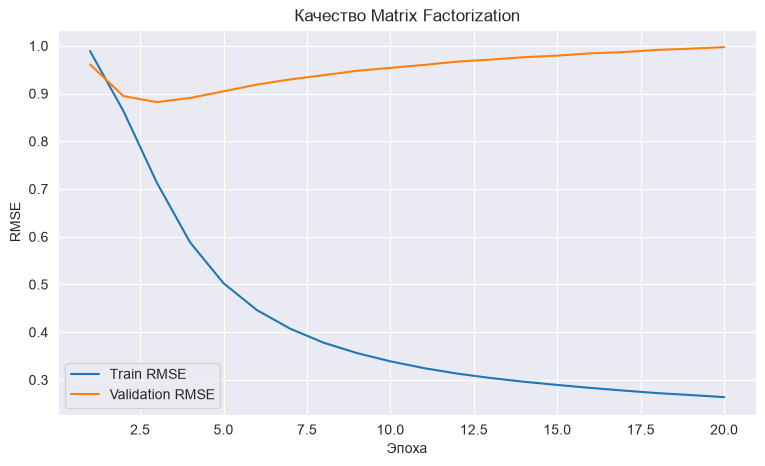

In [10]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_rmse"], label="Train RMSE")
plt.plot(history_df["epoch"], history_df["val_rmse"], label="Validation RMSE")
plt.xlabel("Эпоха")
plt.ylabel("RMSE")
plt.title("Качество Matrix Factorization")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import copy
import numpy as np
import torch
from torch import nn

torch.manual_seed(42)

model = MatrixFactorization(
    n_users=len(user_ids),
    n_movies=len(movie_ids),
    embedding_dim=32
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005,
    weight_decay=1e-5
)

epochs = 20
patience = 3

best_val_rmse = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0
history = []

for epoch in range(1, epochs + 1):
    model.train()
    total_squared_error = 0.0
    total_count = 0

    for users, movies, ratings_batch in train_loader:
        users = users.to(device)
        movies = movies.to(device)
        ratings_batch = ratings_batch.to(device)

        optimizer.zero_grad()

        predictions = model(users, movies)
        loss = criterion(predictions, ratings_batch)

        loss.backward()
        optimizer.step()

        total_squared_error += loss.item() * len(ratings_batch)
        total_count += len(ratings_batch)

    train_rmse = np.sqrt(total_squared_error / total_count)
    val_rmse = np.sqrt(evaluate_mse(model, val_loader))

    history.append({
        "epoch": epoch,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse
    })

    print(
        f"Эпоха {epoch:02d} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {val_rmse:.4f}"
    )

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Ранняя остановка: валидация не улучшается.")
        break

model.load_state_dict(best_state)

print(f"\nЛучшая эпоха: {best_epoch}")
print(f"Лучший Val RMSE: {best_val_rmse:.4f}")

Эпоха 01 | Train RMSE: 0.9892 | Val RMSE: 0.9611
Эпоха 02 | Train RMSE: 0.8635 | Val RMSE: 0.8947
Эпоха 03 | Train RMSE: 0.7137 | Val RMSE: 0.8821
Эпоха 04 | Train RMSE: 0.5880 | Val RMSE: 0.8908
Эпоха 05 | Train RMSE: 0.5026 | Val RMSE: 0.9047
Эпоха 06 | Train RMSE: 0.4463 | Val RMSE: 0.9188
Ранняя остановка: валидация не улучшается.

Лучшая эпоха: 3
Лучший Val RMSE: 0.8821


In [12]:
# Средний рейтинг только по обучающей части
global_mean = fit_df["rating"].mean()

# Предсказание одним и тем же числом для всех примеров
baseline_predictions = np.full(
    len(val_df),
    global_mean,
    dtype=np.float32
)

baseline_rmse = np.sqrt(
    np.mean(
        (val_df["rating"].to_numpy() - baseline_predictions) ** 2
    )
)

# RMSE лучшей обученной модели
model_rmse = np.sqrt(evaluate_mse(model, val_loader))

print(f"Средний рейтинг в train: {global_mean:.4f}")
print(f"Baseline Val RMSE:       {baseline_rmse:.4f}")
print(f"Matrix Factorization:    {model_rmse:.4f}")
print(f"Улучшение RMSE:          {(baseline_rmse - model_rmse):.4f}")

Средний рейтинг в train: 3.5200
Baseline Val RMSE:       1.0419
Matrix Factorization:    0.8821
Улучшение RMSE:          0.1598


In [14]:
catalog = pd.DataFrame({
    "movieId": movie_ids,
    "movie_idx": [movie_to_idx[movie_id] for movie_id in movie_ids]
})

seen_movies = (train_model.groupby("user_idx")["movie_idx"].apply(set).to_dict())

test_positives = (
    test_known[test_known["rating"] >= 4].groupby("user_idx")["movie_idx"].apply(set).to_dict()
)

eval_users = [user_idx for user_idx, positives in test_positives.items() if len(positives) >0]

print("Фильмов в каталоге:", len(catalog))
print("Пользователей для оценки:", len(eval_users))
print("Пользователей с положительными тестовыми оценками:", len(test_positives))

Фильмов в каталоге: 8230
Пользователей для оценки: 591
Пользователей с положительными тестовыми оценками: 591


In [15]:
all_movie_idx = torch.tensor(catalog["movie_idx"].to_numpy(), dtype=torch.long, device=device)

recommendations = {}

model.eval()

with torch.no_grad():
    for user_idx in eval_users:
        user_tensor = torch.full((len(catalog),), user_idx, dtype=torch.long, device=device)
        
        scores = model(user_tensor, all_movie_idx).cpu().numpy()
        
        seen = seen_movies.get(user_idx, set())
        scores[catalog["movie_idx"].isin(seen).to_numpy()] = -np.inf
        
        top_positions = np.argsort(scores)[::-1][:10]
        
        recommendations[user_idx] = (catalog.iloc[top_positions]["movie_idx"].tolist())
        
print("Пользователей с рекомендациями:", len(recommendations))
print("Количество рекомендаций для первого пользователя:", len(recommendations[eval_users[0]]))

Пользователей с рекомендациями: 591
Количество рекомендаций для первого пользователя: 10


In [20]:
def recall_at_k(recommended, relevant, k=10):
    if not relevant:
        return np.nan
    
    recommended_k = recommended[:k]
    hits = len(set(recommended_k) & relevant)
    
    return hits / len(relevant)

def ndcg_at_k(recommended, relevant, k=10):
    recommended_k = recommended[:k]
    
    relevance = np.array(
        [1 if movie_idx in relevant else 0 
         for movie_idx in recommended_k],
        dtype=np.float64
    )
    
    discounts = 1 / np.log2(np.arange(2, len(relevance) + 2))
    dcg = np.sum(relevance * discounts)
    
    ideal_length = min(len(relevant), k)
    ideal_discounts = 1 / np.log2(np.arange(2, ideal_length + 2))
    idcg = np.sum(ideal_discounts)
    
    return dcg / idcg if idcg > 0 else 0.0
    
recalls = []
ndcgs = []

for user_idx in eval_users:
    recommended = recommendations[user_idx]
    relevant = test_positives[user_idx]
    
    recalls.append(recall_at_k(recommended, relevant, k=10))
    ndcgs.append(ndcg_at_k(recommended, relevant, k=10))
    
print(f"Recall@10: {np.mean(recalls):.4f}")
print(f"NDCG@10:   {np.mean(ndcgs):.4f}")

Recall@10: 0.0379
NDCG@10:   0.0553


In [18]:
torch.manual_seed(42)

final_model = MatrixFactorization(
    n_users=len(user_ids),
    n_movies=len(movie_ids),
    embedding_dim=32
).to(device)

final_optimizer = torch.optim.Adam(final_model.parameters(), lr=0.005, weight_decay=1e-5)

final_train_loader = make_loader(train_model, shuffle=True)

for epoch in range(3):
    final_model.train()
    total_squared_error = 0
    total_count = 0
    
    for user_idx, movie_idx, ratings_batch in final_train_loader:
        user_idx = user_idx.to(device)
        movie_idx = movie_idx.to(device)
        ratings_batch = ratings_batch.float().to(device)
        
        final_optimizer.zero_grad()
        
        preds = final_model(user_idx, movie_idx)
        loss = criterion(preds, ratings_batch)
        
        loss.backward()
        final_optimizer.step()
        
        total_squared_error += ((preds.detach() - ratings_batch) ** 2).sum().item()
        total_count += len(ratings_batch)
        
    train_rmse = (total_squared_error / total_count) ** 0.5
    print(f"Epoch {epoch + 1}: Train RMSE = {train_rmse:.4f}")

Epoch 1: Train RMSE = 0.9851
Epoch 2: Train RMSE = 0.8507
Epoch 3: Train RMSE = 0.7043


In [19]:
seen_movies = (train_model.groupby("user_idx")["movie_idx"].apply(set).to_dict())

recommendations = {}

all_movie_idx = torch.tensor(catalog["movie_idx"].to_numpy(), dtype=torch.long, device=device)

final_model.eval()

with torch.no_grad():
    for user_idx in eval_users:
        user_tensor = torch.full((len(catalog),), user_idx, dtype=torch.long, device=device)

        scores = final_model(user_tensor, all_movie_idx).cpu().numpy()

        seen = seen_movies.get(user_idx, set())
        seen_mask = catalog["movie_idx"].isin(seen).to_numpy()
        scores[seen_mask] = -np.inf

        top_positions = np.argsort(scores)[::-1][:10]
        recommendations[user_idx] = (catalog.iloc[top_positions]["movie_idx"].tolist())